# Assignment 2 — House Price Prediction

**Scenario:** You are a data scientist at a real-estate company building a model to
predict house prices from features such as area, number of bedrooms, location, and
age of the house.

**Dataset:** `Housing.csv` (Kaggle: *yasserh/housing-prices-dataset*, 545 rows).

**Approach:** Framed as a supervised **regression** problem. We build a clean
preprocessing + Linear Regression pipeline, evaluate with R² / RMSE / MAE, compare
against a polynomial model, and interpret the coefficients.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

df = pd.read_csv("../data/Housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 1. Explore the data

In [2]:
df.info()
print("\nMissing values:", int(df.isna().sum().sum()))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0


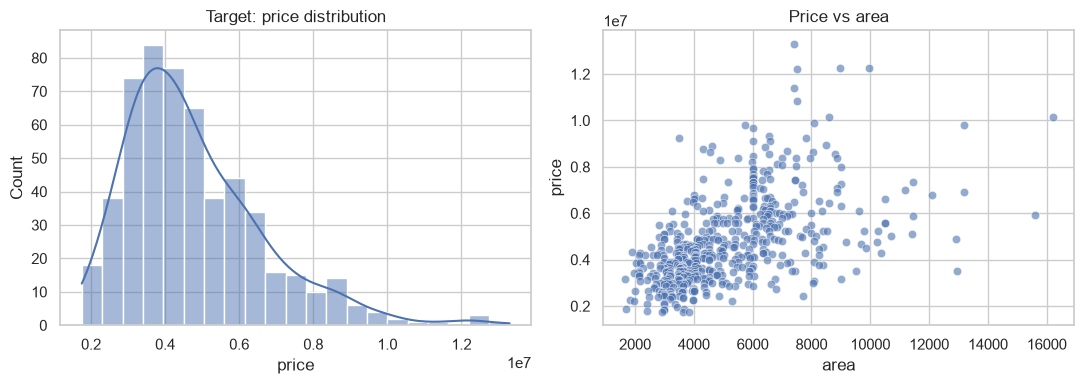

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["price"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Target: price distribution")
sns.scatterplot(data=df, x="area", y="price", ax=axes[1], alpha=0.6)
axes[1].set_title("Price vs area")
plt.tight_layout(); plt.show()

The target is right-skewed and `area` is clearly the dominant driver.
Several columns are categorical (`yes`/`no` flags + `furnishingstatus`).

## 2. Correlation of numeric features

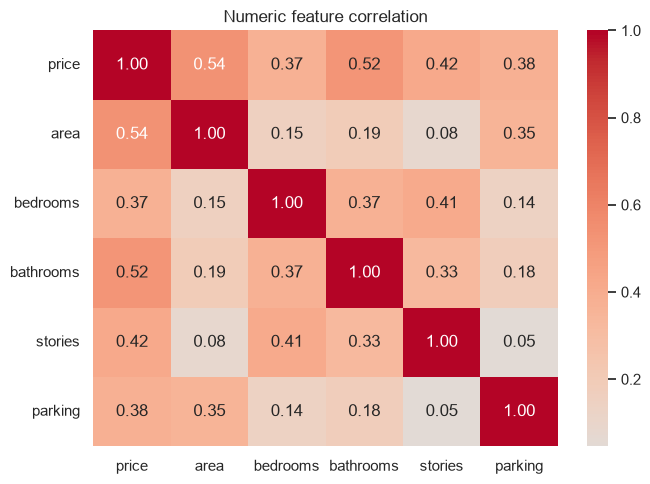

In [4]:
num = df.select_dtypes("number")
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric feature correlation")
plt.tight_layout(); plt.show()

## 3. Preprocessing + train/test split

We split features into numeric and categorical, then build a `ColumnTransformer`
that **scales** numeric features and **one-hot encodes** categoricals, wrapped in a
`Pipeline` so the same transforms apply to train and test with no leakage.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

X = df.drop(columns=["price"])
y = df["price"]

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("object").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Numeric: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
Train: (436, 12) Test: (109, 12)


/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_4144/1885680285.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes("object").columns.tolist()


## 4. Train the Linear Regression model

In [6]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    r2 = r2_score(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    mae = mean_absolute_error(yte, pred)
    print(f"{name:22s}  R2={r2:.3f}  RMSE={rmse:,.0f}  MAE={mae:,.0f}")
    return {"model": name, "R2": r2, "RMSE": rmse, "MAE": mae}, pred

lin = Pipeline([("pre", pre), ("reg", LinearRegression())])
res_lin, pred_lin = evaluate("LinearRegression", lin, X_train, y_train, X_test, y_test)

LinearRegression        R2=0.653  RMSE=1,324,507  MAE=970,043


## 5. Diagnostic plots

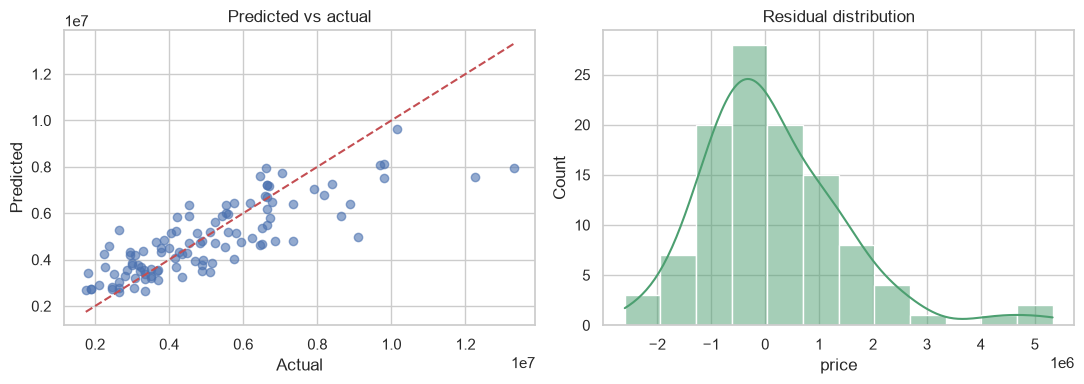

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, pred_lin, alpha=0.6, color="#4C72B0")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted")
axes[0].set_title("Predicted vs actual")

resid = y_test - pred_lin
sns.histplot(resid, kde=True, ax=axes[1], color="#4C9F70")
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

## 6. Compare with a Polynomial model

To check whether non-linear relationships help, we add degree-2 polynomial
features on the numeric columns.

In [8]:
from sklearn.preprocessing import PolynomialFeatures

pre_poly = ColumnTransformer([
    ("num", Pipeline([("scale", StandardScaler()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False))]), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])
poly = Pipeline([("pre", pre_poly), ("reg", LinearRegression())])
res_poly, _ = evaluate("Polynomial(deg=2)", poly, X_train, y_train, X_test, y_test)

pd.DataFrame([res_lin, res_poly]).set_index("model")

Polynomial(deg=2)       R2=0.650  RMSE=1,330,810  MAE=978,314


,R2,RMSE,MAE
model,,,
LinearRegression,0.652924,1.324507e+06,970043.403920
Polynomial(deg=2),0.649613,1.330810e+06,978314.387222


## 7. Interpret the coefficients

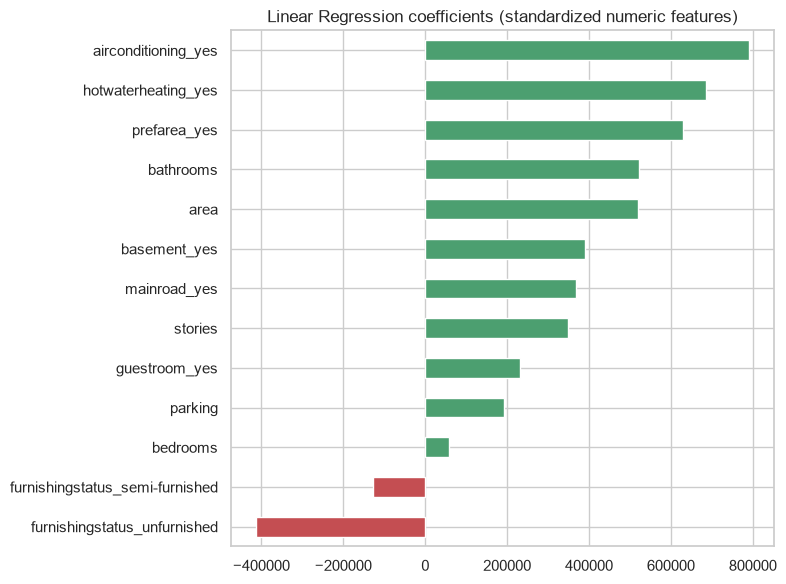

furnishingstatus_unfurnished      -413645.062228
furnishingstatus_semi-furnished   -126881.817585
bedrooms                            57349.559419
parking                            192005.953667
guestroom_yes                      231610.037176
stories                            349251.438906
mainroad_yes                       367919.947680
basement_yes                       390251.176181
area                               519552.416340
bathrooms                          521879.027748
prefarea_yes                       629890.565313
hotwaterheating_yes                684649.885339
airconditioning_yes                791426.735843
dtype: float64

In [9]:
lin.fit(X_train, y_train)
feat_names = (num_cols +
    list(lin.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(cat_cols)))
coefs = pd.Series(lin.named_steps["reg"].coef_, index=feat_names).sort_values()

plt.figure(figsize=(8, 6))
coefs.plot.barh(color=np.where(coefs > 0, "#4C9F70", "#C44E52"))
plt.title("Linear Regression coefficients (standardized numeric features)")
plt.tight_layout(); plt.show()
coefs

## Conclusion

- A clean preprocessing pipeline (scaling + one-hot encoding) with **Linear
  Regression** explains the majority of the variance in house prices (see R²
  above).
- **Area, air-conditioning, bathrooms, and preferred-area location** are the
  strongest positive drivers of price.
- The degree-2 polynomial model did not meaningfully beat plain linear
  regression, indicating the relationships are largely linear — a simpler model is
  preferable here (and is explored further with regularization in Assignment 3).
